# ЛР 1. Прогнозирование отопительной и охлаждающей нагрузки
**Датасет:** `marvel.csv`.

**Участники:** укажите ФИО.

## Постановка задачи
По параметрам объекта необходимо предсказать две величины: отопительную нагрузку (`Heating Load`) и охлаждающую нагрузку (`Cooling Load`). Это задача регрессии, поскольку результат — числовые значения.

Объект исследования — одна конфигурация, представленная строкой таблицы. Вход модели — геометрические параметры, ориентация и характеристики остекления. Выход модели — два числа: прогноз нагрузки на отопление и охлаждение.

Предполагаемый пользователь — инженер, которому нужно сравнивать конфигурации по нагрузкам до проведения подробных расчетов. В файле есть названия `Reactor Wall Area` и `Reactor Roof Area`; точный смысл объекта и единицы измерения нужно уточнить по описанию варианта.

В этой работе выполняются первые два этапа CRISP-DM: понимание задачи и изучение данных. Затем данные делятся на обучение и тест.

## Содержание ноутбука
1. [Формирование окружения](#environment)
2. [Описание признаков](#features)
3. [Research: загрузка и анализ данных](#research)
4. [Production: подготовка и разделение](#production)
5. [Выводы](#conclusions)

## Формирование окружения <a id="environment"></a>
Используется Python 3.12.5. Точные версии библиотек записаны в `requirements.txt`. Для повторного запуска на macOS/Linux создайте виртуальное окружение и установите зависимости:

```bash
python3.12 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
python -m ipykernel install --user --name lr1-marvel --display-name "Python (LR1 Marvel)"
jupyter lab
```

В Jupyter выберите ядро `Python (LR1 Marvel)`. Поместите `marvel.csv` рядом с ноутбуком. Команды для Windows приведены в README.

In [1]:
from pathlib import Path
import platform
from importlib.metadata import version

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from IPython.display import display

seed = 42
print("Python:", platform.python_version())
for package in ["pandas", "numpy", "scikit-learn", "matplotlib"]:
    print(package, version(package))

Matplotlib is building the font cache; this may take a moment.


Python: 3.12.5
pandas 3.0.2
numpy 2.4.5
scikit-learn 1.8.0
matplotlib 3.10.9


## Описание признаков <a id="features"></a>
| Признак | Описание | Тип | Роль |
|---|---|---|---|
| Relative Compactness | Относительная компактность | Вещественный | Входной |
| Surface Area | Площадь поверхности | Вещественный | Входной |
| Reactor Wall Area | Площадь стен | Вещественный | Входной |
| Reactor Roof Area | Площадь крыши | Вещественный | Входной |
| Overall Height | Общая высота | Вещественный | Входной |
| Orientation | Код ориентации | Категориальный | Входной |
| Glazing Area | Доля остекления | Вещественный | Входной |
| Glazing Area Distribution | Код распределения остекления | Категориальный | Входной |
| Heating Load | Отопительная нагрузка | Вещественный | Целевой |
| Cooling Load | Охлаждающая нагрузка | Вещественный | Целевой |

`Orientation` и `Glazing Area Distribution` записаны числами, но обозначают категории. Обе нагрузки исключаются из входных признаков: их требуется предсказать.

# Раздел 1. Обработка входных данных и датасета
## 1.1. Research <a id="research"></a>
### 1.1.1. Загрузка исходных данных
Прочитаем CSV с помощью pandas. В этом файле столбцы разделены точкой с запятой, поэтому указываем `sep=";"`. Выведем первые строки и размер таблицы.

In [2]:
df = pd.read_csv("marvel.csv", sep=";", encoding="utf-8")
display(df.head())
print("Строк:", df.shape[0], "Столбцов:", df.shape[1])

,Relative Compactness,Surface Area,Reactor Wall Area,Reactor Roof Area,Overall Height,Orientation,Glazing Area,Glazing Area Distribution,Heating Load,Cooling Load
0,0.98,514.5,294.0,110.25,7.0,2.0,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3.0,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,NaN,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5.0,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,NaN,2.0,0.0,0,20.84,28.28


Строк: 768 Столбцов: 10


### 1.1.2. Анализ типов данных и значений признаков
Проверим типы столбцов, количество уникальных значений и пропуски.

In [3]:
df.info()
display(pd.DataFrame({
    "Тип": df.dtypes.astype(str),
    "Уникальных значений": df.nunique(),
    "Пропусков": df.isna().sum(),
    "Пропусков, %": (df.isna().mean() * 100).round(2)
}))
print("Полных дубликатов:", df.duplicated().sum())
print("Повторов по входным признакам:", df.iloc[:, :8].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Relative Compactness       691 non-null    float64
 1   Surface Area               768 non-null    float64
 2   Reactor Wall Area          691 non-null    float64
 3   Reactor Roof Area          768 non-null    float64
 4   Overall Height             691 non-null    float64
 5   Orientation                691 non-null    float64
 6   Glazing Area               768 non-null    float64
 7   Glazing Area Distribution  768 non-null    int64  
 8   Heating Load               768 non-null    float64
 9   Cooling Load               768 non-null    float64
dtypes: float64(9), int64(1)
memory usage: 60.1 KB


,Тип,Уникальных значений,Пропусков,"Пропусков, %"
Relative Compactness,float64,12,77,10.03
Surface Area,float64,12,0,0.00
Reactor Wall Area,float64,7,77,10.03
Reactor Roof Area,float64,4,0,0.00
Overall Height,float64,2,77,10.03
Orientation,float64,4,77,10.03
Glazing Area,float64,4,0,0.00
Glazing Area Distribution,int64,6,0,0.00
Heating Load,float64,586,0,0.00
Cooling Load,float64,636,0,0.00


Полных дубликатов: 0
Повторов по входным признакам: 7


В таблице 768 строк и 10 столбцов. В четырех признаках по 77 пропусков: `Relative Compactness`, `Reactor Wall Area`, `Overall Height`, `Orientation`. В целевых признаках пропусков нет.

Полных дубликатов нет. Есть 7 повторов по входным признакам с разными нагрузками; у этих строк отсутствует ориентация. Поэтому удалять их как одинаковые объекты не будем.

Проверим коды категорий и диапазоны числовых признаков.

In [4]:
categorical_columns = ["Orientation", "Glazing Area Distribution"]
y_columns = ["Heating Load", "Cooling Load"]
numeric_columns = [column for column in df.columns if column not in categorical_columns]

for column in categorical_columns:
    print(column, sorted(df[column].dropna().unique()))
display(df[numeric_columns].describe().T)

Orientation [np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
Glazing Area Distribution [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


,count,mean,std,min,25%,50%,75%,max
Relative Compactness,691.0,0.763357,0.106581,0.62,0.6600,0.74,0.8400,0.98
Surface Area,768.0,671.708333,88.086116,514.50,606.3750,673.75,741.1250,808.50
Reactor Wall Area,691.0,319.528220,43.545989,245.00,294.0000,318.50,343.0000,416.50
Reactor Roof Area,768.0,176.604167,45.165950,110.25,140.8750,183.75,220.5000,220.50
Overall Height,691.0,5.257598,1.751251,3.50,3.5000,7.00,7.0000,7.00
Glazing Area,768.0,0.234375,0.133221,0.00,0.1000,0.25,0.4000,0.40
Heating Load,768.0,22.307201,10.090196,6.01,12.9925,18.95,31.6675,43.10
Cooling Load,768.0,24.587760,9.513306,10.90,15.6200,22.08,33.1325,48.03


`Orientation` принимает коды 2–5, `Glazing Area Distribution` — 0–5. Их преобразуем в категориальный тип. Все площади, высота и нагрузки положительны. Доля остекления находится в диапазоне от 0 до 0,4; ноль здесь допустим.

Пропуски пока оставим. Их заполнение будет выполняться в следующей работе после разделения, используя только обучающие данные.

## 1.2. Production <a id="production"></a>
### 1.2.1. Подготовка типов и разделение выборки
Здесь собран итоговый код загрузки и разделения. Он соответствует этапу ЛР 1.

На обучение выделим 80% данных, на тест — 20%. `random_state=seed` позволяет получить то же разделение при повторном запуске. Перемешивание подходит, поскольку в таблице нет дат и временной последовательности. Целевые значения непрерывные, поэтому стратификацию по классам не используем.

In [5]:
df = pd.read_csv("marvel.csv", sep=";", encoding="utf-8")
for column in categorical_columns:
    df[column] = df[column].astype("Int64").astype("category")

train_df, test_df = train_test_split(
    df, test_size=0.20, random_state=seed, shuffle=True
)

X_train = train_df.drop(columns=y_columns)
X_test = test_df.drop(columns=y_columns)
y_train = train_df[y_columns].copy()
y_test = test_df[y_columns].copy()

assert set(train_df.index).isdisjoint(test_df.index)
assert len(train_df) + len(test_df) == len(df)
assert not X_train.columns.isin(y_columns).any()
assert not df[y_columns].isna().any().any()

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

X_train: (614, 8) y_train: (614, 2)
X_test: (154, 8) y_test: (154, 2)


Получены 614 обучающих и 154 тестовых объекта. В X находятся 8 входных признаков, в y — 2 целевых. Индексы частей не пересекаются.

Сохраним части выборки в отдельные файлы. `source_row` в сохраненных файлах — исходный индекс строки; его не нужно использовать как входной признак.

In [6]:
split_dir = Path("splits")
split_dir.mkdir(exist_ok=True)
for name, frame in {
    "X_train": X_train, "X_test": X_test,
    "y_train": y_train, "y_test": y_test
}.items():
    frame.to_csv(split_dir / f"{name}.csv", sep=";", index_label="source_row")

### 1.2.2. Первичный анализ обучающей выборки
Посмотрим распределения числовых признаков только на train. Тест оставим для проверки будущей модели.

,count,mean,std,min,25%,50%,75%,max
Relative Compactness,550.0,0.760782,0.106526,0.62,0.6600,0.74,0.820,0.98
Surface Area,614.0,673.829805,88.161209,514.50,612.5000,686.00,759.500,808.50
Reactor Wall Area,549.0,319.794171,43.018059,245.00,294.0000,318.50,343.000,416.50
Reactor Roof Area,614.0,177.505293,44.960238,110.25,147.0000,220.50,220.500,220.50
Overall Height,551.0,5.234120,1.751518,3.50,3.5000,3.50,7.000,7.00
Glazing Area,614.0,0.235423,0.134152,0.00,0.1000,0.25,0.400,0.40
Heating Load,614.0,22.155033,10.054280,6.01,12.9775,18.25,31.545,43.10
Cooling Load,614.0,24.410765,9.476566,10.90,15.6400,21.50,32.920,48.03


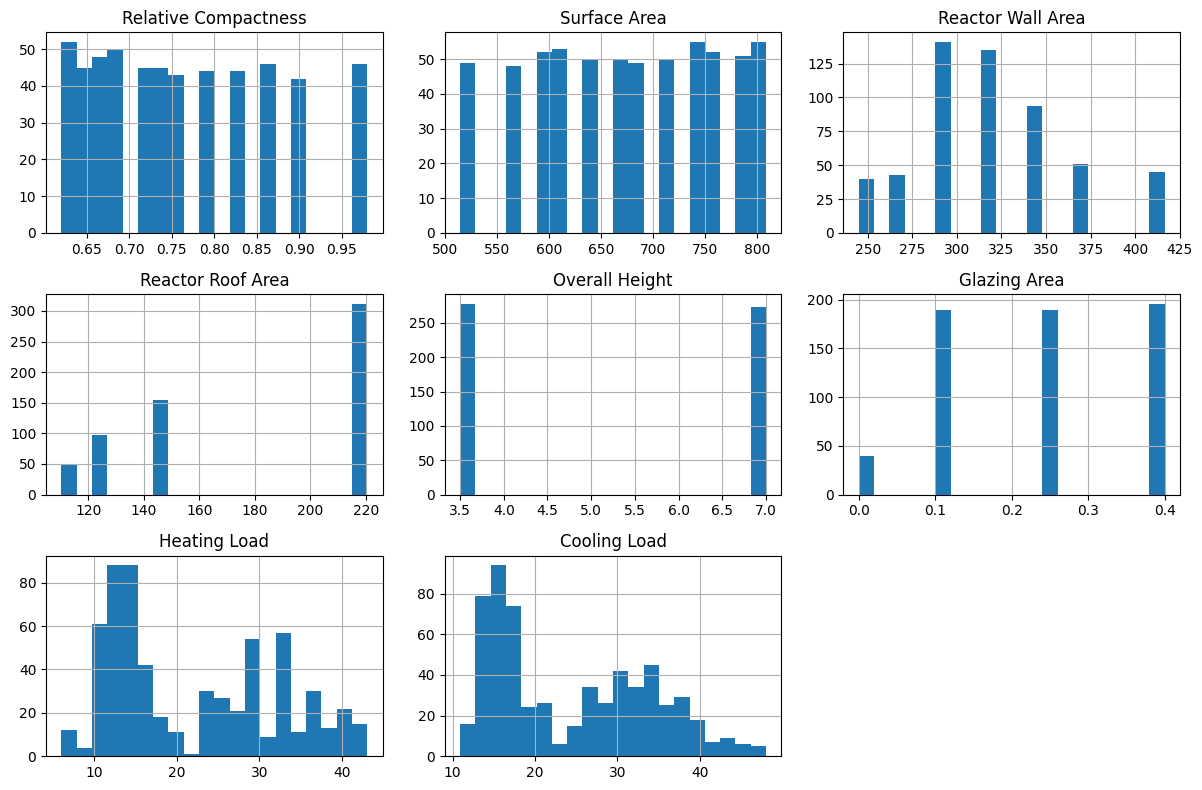

In [7]:
display(train_df[numeric_columns].describe().T)
train_df[numeric_columns].hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

Параметры геометрии имеют ограниченный набор значений. Некоторые конфигурации похожи и могут попасть в разные части выборки. Поэтому этот тест проверяет прогноз для конфигураций из того же набора, а не для любых новых типов объектов.

Большие значения нагрузок пока не удаляем: они могут соответствовать допустимым конфигурациям.

## 1.3. Выводы по разделу <a id="conclusions"></a>
1. Сформулирована задача регрессии: прогноз двух нагрузок по восьми параметрам объекта.
2. Данные загружены из `marvel.csv`, проверены типы и значения признаков.
3. Найдены пропуски в четырех входных столбцах; полных дубликатов нет.
4. Два признака приведены к категориальному типу.
5. Выборка разделена на 614 обучающих и 154 тестовых объекта с фиксированным seed.

Далее нужно заполнить пропуски и закодировать категории, обучая предобработку только на train.